<a href="https://colab.research.google.com/github/BrunoCapron/AprendizadoPorRefor-o/blob/main/trabalhoEQE778/trabalho_SAC_VdV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho computacional: controle do reator de Van de Vusse com SAC

**Aprendizado de máquina**

## 1. Contexto

Em Delou et al. (2023), um controlador RL actor-critic usando **combinações lineares de RBFs** para aproximação da função de valor e da política foi aplicado ao reator CSTR de Van de Vusse (VdV). O objetivo de controle é:

- **rastrear** a vazão molar de B, $F_B = F\,C_B$, em $F_B^{SP} = 2000$ mol/h;
- **maximizar** $C_B$ ;
- manipulando a vazão de alimentação $F$ e a temperatura da camisa $T_k$ (por incrementos limitados a ±1,2 L/h e ±0,48 K por passo de 0,01 h);
- rejeitando perturbações **não medidas** na temperatura de alimentação $T_{in}$ (nominal: 100 °C), em simulações de 120 h.

Neste trabalho você vai **treinar um agente SAC (Soft Actor-Critic)** e compará-lo com o RL-RBF do artigo (*baseline*), tentando obter **o melhor desempenho possível** dentro das regras abaixo.

## 2. Cenários de avaliação

| Cenário | Perturbação em $T_{in}$ | Uso |
|---|---|---|
| `validacao` | 100 → 90 °C em $t = 60$ h (cenário do artigo) | validação: pode ser usado livremente para desenvolver e ajustar o agente |
| `teste` | 100 → 108 °C em $t = 30$ h e → 85 °C em $t = 80$ h | avaliação final: **não use para ajustar** recompensa ou hiperparâmetros; rode uma vez ao final |
| `dificil` | $T_{in}$: 100 → 70 °C em $t = 20$ h, → 120 °C em $t = 55$ h e → 65 °C em $t = 90$ h | teste severo, mas do tipo sorteado no treino quando `DIST_PROB > 0` (1 a 3 degraus com $T_{in}$ em 55-135 °C): um agente treinado com perturbações **já viu** situações desse tipo. O RL-RBF do baseline, treinado sem perturbações, tem desempenho ruim aqui. **Também não use para ajustar.** |

Nos três cenários o processo parte do mesmo regime permanente ($F = 1000$ L/h) e o agente nunca vê $T_{in}$, apenas $[C_B, C_A, T, F, T_k]$.

## 3. O que é fornecido

| Item | Descrição |
|---|---|
| Ambiente `VdVEnv` | Simulador Gymnasium do VdV (Eqs. 31-34 e Tabela 1 do artigo). **Não altere.** |
| `SCENARIOS`, `run_scenario`, `metrics` | Cenários, execução e métricas. **Não altere.** |
| `baselines_vdv.py` | RL-RBF do artigo em Python (actor-critic com 1680 RBFs gaussianas). |
| `baselines.npz`, `rlrbf_pesos.npz` | Trajetórias do RL-RBF nos dois cenários e pesos treinados (se não existirem, o notebook os gera). |
| `my_reward` | Função de recompensa inicial, inspirada na Eq. 35 do artigo. **Você pode (e deve) modificá-la.** |

## 4. Regras

1. **Orçamento de interação:** no máximo $3 \times 10^6$ passos de simulação de 0,01 h por treinamento (o mesmo do RL-RBF: 500 episódios × 6000 passos).
2. O agente só pode observar as variáveis medidas $[C_B, C_A, T, F, T_k]$. **Não use as equações do modelo** no agente.
3. **Pode alterar:** recompensa, hiperparâmetros do SAC, arquitetura da rede, `action_repeat` (1 a 20), duração dos episódios, probabilidade de perturbação durante o treino (`dist_prob`), normalização.
4. **Não pode alterar:** física, limites, $\Delta t$, cenários e métrica.
5. A configuração final deve ser treinada com **no mínimo 3 sementes** e reportada como média ± desvio padrão.
6. O professor pode substituir os cenários `teste` e `dificil` por cenários ocultos. Evite sobreajustar.

## 5. Métrica

$$J = \underbrace{\int_0^{120} \frac{|F_B - F_B^{SP}|}{F_B^{SP}}\,dt}_{\text{erro de rastreio}} \;+\; \underbrace{\int_0^{120} \frac{\max(0,\,C_B^* - C_B)}{C_B^*}\,dt}_{\text{perda de } C_B}$$

com $C_B^* = 1{,}1295$ mol/L (máximo de $C_B$ em regime permanente com $F_B = F_B^{SP}$, que não depende de $T_{in}$). Ambas as parcelas são adimensionais, em horas. **Quanto menor J, melhor.** Foram também reportados $J$ após 15 h (fase regulatória, sem a partida) e o $C_B$ médio nas últimas 10 h.

## 6. Entregáveis

Este notebook executado (com gráficos e tabelas) e o preenchimento da seção de análise (Parte 3).

> **Nota sobre as condições iniciais.** A Tabela 2 do artigo lista $T_k = 100$ °C, mas com as Eqs. 31-34 e a Tabela 1 esse valor não conduz ao regime permanente indicado ($C_A = 3{,}856$, $C_B = 0{,}6561$ mol/L, $T = 119{,}488$ °C). Aqui o estado inicial é o regime permanente com $F = 1000$ L/h e $T_k \approx 162{,}7$ °C, que reproduz esses valores.

## Configuração

In [1]:
!pip -q install gymnasium stable-baselines3
import numpy as np, matplotlib.pyplot as plt, pandas as pd, os, math
import gymnasium as gym
from gymnasium import spaces
np.set_printoptions(precision=4, suppress=True)

## Ambiente, cenários e métricas (não alterar)

O código abaixo é gravado em `vdv_env.py` (também usado pelo RL-RBF) e importado em seguida.

In [2]:
%%writefile vdv_env.py
import math
import numpy as np
import gymnasium as gym
from gymnasium import spaces

# ---------------- Parâmetros (Tabela 1 do artigo) ----------------
P = dict(k10=1.287e12, k20=1.287e12, k30=9.043e9, E1=-9758.3, E2=-9758.3, E3=-8560.0,
         dH1=4.2, dH2=-11.0, dH3=-41.85, V=10.0, cp=3.01, rho=0.932, AR=0.215, kw=4032.0)
CA_IN, CB_IN, T_IN_NOM, T_IN_DIST = 5.1, 0.0, 100.0, 90.0
DT = 0.01                       # h, tempo de amostragem do artigo
FB_SP = 2000.0                  # mol/h
CB_STAR = 1.1295                # mol/L, máx. de CB com FB = FB_SP em regime permanente (independe de Tin)
DF_MAX, DTK_MAX = 1.2, 0.48     # limites de incremento por DT (L/h e K)
F_LIM, TK_LIM = (500.0, 2500.0), (20.0, 720.0)

def _rhs(CA, CB, T, F, Tk, Tin):
    TK = T + 273.15
    k1 = P['k10'] * math.exp(P['E1'] / TK)
    k2 = P['k20'] * math.exp(P['E2'] / TK)
    k3 = P['k30'] * math.exp(P['E3'] / TK)
    q = F / P['V']
    rc = P['rho'] * P['cp']
    dCA = q * (CA_IN - CA) - k1 * CA - k3 * CA**2
    dCB = q * (CB_IN - CB) + k1 * CA - k2 * CB
    dT = (k1*CA*(-P['dH1']) + k2*CB*(-P['dH2']) + k3*CA**2*(-P['dH3'])) / rc \
         + q * (Tin - T) + P['kw'] * P['AR'] / (rc * P['V']) * (Tk - T)
    return dCA, dCB, dT

def _nsub(CA, CB, T, F):
    """Nº de subpassos RK4 por DT, a partir de uma estimativa do maior autovalor (cinética rígida em reator quente)."""
    TK = T + 273.15
    k1 = P['k10'] * math.exp(P['E1'] / TK); k2 = P['k20'] * math.exp(P['E2'] / TK); k3 = P['k30'] * math.exp(P['E3'] / TK)
    q = F / P['V']; rc = P['rho'] * P['cp']
    heat = (k1*CA*abs(P['dH1']) + k2*CB*abs(P['dH2']) + k3*CA**2*abs(P['dH3'])) / rc
    lam = q + k1 + k2 + 2*k3*abs(CA) + P['kw']*P['AR']/(rc*P['V']) + heat * 9800.0 / TK**2
    return int(min(400, max(4, math.ceil(DT * lam / 0.8))))

def _rk4(x, F, Tk, Tin, h):
    k1 = _rhs(*x, F, Tk, Tin)
    k2 = _rhs(*(x[i] + 0.5*h*k1[i] for i in range(3)), F, Tk, Tin)
    k3 = _rhs(*(x[i] + 0.5*h*k2[i] for i in range(3)), F, Tk, Tin)
    k4 = _rhs(*(x[i] + h*k3[i] for i in range(3)), F, Tk, Tin)
    return tuple(x[i] + h/6*(k1[i] + 2*k2[i] + 2*k3[i] + k4[i]) for i in range(3))

def steady_state(F, Tk, Tin=T_IN_NOM, x0=(3.856, 0.6561, 119.488), t_end=10.0, h=0.005):
    """Regime permanente (ramo estável) obtido por integração até t_end."""
    x = x0
    for _ in range(int(t_end / h)):
        x = _rk4(x, F, Tk, Tin, h)
    return x

TK_NOM = 162.7   # °C: Tk que leva a T = 119.49 °C com F = 1000 L/h (ver nota no enunciado)

class VdVEnv(gym.Env):
    """CSTR de Van de Vusse. Estado do artigo: s = [CB, CA, T, F, Tk].
    Ação normalizada a in [-1,1]^2  ->  [dF, dTk] = a * [1.2, 0.48] por DT (cada decisão é mantida `action_repeat` passos de DT).
    """
    metadata = {}

    def __init__(self, reward_fn=None, action_repeat=10, episode_steps=3000, mode="train",
                 dist_prob=0.0, dist_step=6000, Tin_dist=T_IN_DIST, schedule=None, dist_range=(55.0, 135.0)):
        super().__init__()
        self.reward_fn = reward_fn or default_reward
        self.R = action_repeat
        self.episode_steps = episode_steps      # em passos de DT
        self.mode = mode                        # "train" (estado inicial aleatório) ou "eval" (cenário do artigo)
        self.dist_prob = dist_prob              # prob. de um episódio de treino ter 1 a 3 degraus aleatórios em Tin
        self.dist_range = dist_range            # faixa (°C) dos valores de Tin sorteados no treino
        self.dist_step = dist_step
        self.Tin_dist = Tin_dist                # temperatura de alimentação após a perturbação
        self.schedule = schedule                # opcional: lista [(passo, Tin), ...] (substitui dist_step/Tin_dist)
        self.observation_space = spaces.Box(-np.inf, np.inf, (5,), np.float32)
        self.action_space = spaces.Box(-1.0, 1.0, (2,), np.float32)
        self._lo = np.array([0.0, 0.0, 90.0, F_LIM[0], TK_LIM[0]])
        self._hi = np.array([1.2, 5.1, 170.0, F_LIM[1], TK_LIM[1]])

    # --- observação normalizada em ~[-1, 1] ---
    def _obs(self):
        s = np.array([self.CB, self.CA, self.T, self.F, self.Tk])
        return (2 * (s - self._lo) / (self._hi - self._lo) - 1).astype(np.float32)

    def _tin(self, k):
        Tin = T_IN_NOM
        for ks, Ts in self._sched:
            if k >= ks: Tin = Ts
        return Tin

    def trajectory(self, n_steps):
        """Trajetória em resolução DT. Se o episódio terminou antes (fuga térmica), o restante é preenchido com
        F_B = C_B = 0 (reator perdido), o que penaliza fortemente J; `falha_em_h` informa o instante da falha."""
        h = np.array(self.history)
        tr = dict(t=h[:, 0], FB=h[:, 1], CB=h[:, 2], F=h[:, 3], Tk=h[:, 4], T=h[:, 5])
        if len(h) < n_steps + 1:
            m = n_steps + 1 - len(h)
            tr['falha_em_h'] = float(h[-1, 0])
            tr['t'] = np.arange(n_steps + 1) * DT
            for v in ('F', 'Tk', 'T'): tr[v] = np.concatenate([tr[v], np.full(m, tr[v][-1])])
            for v in ('FB', 'CB'): tr[v] = np.concatenate([tr[v], np.zeros(m)])
        return tr

    @property
    def FB(self):
        return self.F * self.CB

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if self.mode == "eval":
            self.F, self.Tk = 1000.0, TK_NOM
            x = steady_state(self.F, self.Tk)
            self._sched = self.schedule if self.schedule else [(self.dist_step, self.Tin_dist)]
        else:
            while True:
                F = self.np_random.uniform(*F_LIM)
                Tk = self.np_random.uniform(*TK_LIM)
                try:
                    x = steady_state(F, Tk, t_end=6.0, h=0.005)
                except (OverflowError, ValueError, ZeroDivisionError):
                    continue
                if 90 < x[2] < 200 and min(x[0], x[1]) > 0:
                    break
            self.F, self.Tk = F, Tk
            self._sched = []
            if self.np_random.random() < self.dist_prob:
                n = int(self.np_random.integers(1, 4))
                ks = sorted(set(int(k) for k in self.np_random.integers(300, self.episode_steps, n)))
                self._sched = [(k, float(self.np_random.uniform(*self.dist_range))) for k in ks]
        self.CA, self.CB, self.T = x
        self.k = 0
        self.history = [(0.0, self.FB, self.CB, self.F, self.Tk, self.T)]
        return self._obs(), {}

    def step(self, action):
        a = np.clip(np.asarray(action, dtype=float), -1, 1)
        dF, dTk = a[0] * DF_MAX, a[1] * DTK_MAX
        prev = dict(FB=self.FB, CB=self.CB, F=self.F, Tk=self.Tk, T=self.T)
        bad = False
        for _ in range(self.R):
            self.F = float(np.clip(self.F + dF, *F_LIM))
            self.Tk = float(np.clip(self.Tk + dTk, *TK_LIM))
            Tin = self._tin(self.k)
            x = (self.CA, self.CB, self.T)
            try:
                # passos menores quando o reator está quente (cinética rígida): evita instabilidade numérica do RK4
                nsub = _nsub(self.CA, self.CB, self.T, self.F)
                for _ in range(nsub):
                    x = _rk4(x, self.F, self.Tk, Tin, DT / nsub)
            except (OverflowError, ValueError, ZeroDivisionError):
                x = (self.CA, self.CB, 1e3)               # fuga térmica: estado inválido
            self.CA, self.CB, self.T = x
            self.k += 1
            self.history.append((self.k * DT, self.FB, self.CB, self.F, self.Tk, self.T))
            if not (self.T < 250 and self.CA > -1e-3 and self.CB > -1e-3):
                bad = True
                break
        curr = dict(FB=self.FB, CB=self.CB, F=self.F, Tk=self.Tk, T=self.T)
        r = self.reward_fn(prev, curr)
        if bad:
            r -= 10.0
        truncated = self.k >= self.episode_steps
        return self._obs(), float(r), bad, truncated, {}

# ---------------- Recompensa padrão (inspirada na Eq. 35 do artigo) ----------------
W, EPS, REWARD_SCALE = 2500.0, 150.0, 1.0 / 50.0
def default_reward(prev, curr):
    e_prev, e_curr = abs(prev['FB'] - FB_SP), abs(curr['FB'] - FB_SP)
    act = 1 - math.tanh(e_curr / EPS)
    return REWARD_SCALE * ((e_prev - e_curr) + W * (curr['CB'] - prev['CB']) * act)

# ---------------- Avaliação ----------------
# Cada cenário é um cronograma de degraus em Tin: [(passo de 0,01 h, Tin em °C), ...]. Duração: 120 h.
SCENARIOS = {
    "validacao": [(6000, 90.0)],                    # cenário do artigo: Tin 100 -> 90 °C em t = 60 h
    "teste":   [(3000, 108.0), (8000, 85.0)],     # Tin 100 -> 108 °C em t = 30 h e -> 85 °C em t = 80 h
    # difícil: três degraus de Tin (70, 120 e 65 °C). É uma realização do tipo de perturbação sorteada no treino
    # (1 a 3 degraus com Tin em [55, 135] °C quando DIST_PROB > 0), mas bem mais severa que a do artigo.
    "dificil": [(2000, 70.0), (5500, 120.0), (9000, 65.0)],
}

def run_scenario(policy, scenario="validacao", n_steps=12000, action_repeat=10):
    """policy: obs -> ação em [-1,1]^2. `scenario`: nome em SCENARIOS ou uma lista [(passo, Tin), ...].
    Retorna dict com trajetórias em resolução DT."""
    sched = SCENARIOS[scenario] if isinstance(scenario, str) else scenario
    env = VdVEnv(mode="eval", action_repeat=action_repeat, episode_steps=n_steps, schedule=sched)
    obs, _ = env.reset()
    done = False
    while not done:
        obs, r, term, trunc, _ = env.step(policy(obs))
        done = term or trunc
    return env.trajectory(n_steps)

def metrics(tr):
    """J = erro relativo de F_B + perda relativa de C_B (ambos em h; menor é melhor), mais métricas auxiliares."""
    t, FB, CB = tr['t'], tr['FB'], tr['CB']
    dt = np.diff(t, prepend=t[0]); dt[0] = 0
    e_fb = np.abs(FB - FB_SP) / FB_SP * dt
    l_cb = np.maximum(0, CB_STAR - CB) / CB_STAR * dt
    reg = t >= 15          # fase "regulatória": exclui a partida (~15 h) e mantém as perturbações
    return dict(J=e_fb.sum() + l_cb.sum(), IAE_FB_h=e_fb.sum(), perda_CB_h=l_cb.sum(),
                J_apos_15h=e_fb[reg].sum() + l_cb[reg].sum(),
                CB_medio_final=float(CB[t >= t[-1] - 10].mean()))

Writing vdv_env.py


In [3]:
import vdv_env
from vdv_env import *

## Função de recompensa (você pode modificar)

A versão padrão segue a Eq. 35 do artigo: recompensa a **redução** do erro $|F_B - F_B^{SP}|$ dentro da decisão e, quando $F_B$ está próximo do setpoint (ativação por $\tanh$), recompensa o **aumento** de $C_B$. `prev` e `curr` são dicionários com `FB, CB, F, Tk, T` no início e no fim de cada decisão do agente.

In [4]:
W, EPS, REWARD_SCALE = 2500.0, 150.0, 1.0 / 50.0

def my_reward(prev, curr):
    e_prev, e_curr = abs(prev['FB'] - FB_SP), abs(curr['FB'] - FB_SP)
    act = 1 - math.tanh(e_curr / EPS)
    return REWARD_SCALE * ((e_prev - e_curr) + W * (curr['CB'] - prev['CB']) * act)

REWARD_FN = my_reward      # é esta função que o treino do SAC usa

# Parte 1: o baseline RL-RBF

O RL-RBF do artigo está implementado em `baselines_vdv.py` (célula abaixo): actor-critic episódico com traços de elegibilidade e 1680 RBFs gaussianas sobre $[C_B, C_A, T, F, T_k]$ (Tabelas 3, 4 e 6 do artigo; 500 episódios × 6000 passos, ~10-15 min de treino). Os pesos treinados (`rlrbf_pesos.npz`) são fornecidos.

Note que o RL-RBF foi treinado **sem perturbações** em $T_{in}$. Foi adicionada uma **referência de malha aberta** (aplica $F^*\approx 1770$ L/h e $T_k^*\approx 430$ °C, que dão $F_B = 2000$ e $C_B$ máximo com $T_{in} = 100$ °C), que mostra por que a realimentação é necessária.

In [5]:
%%writefile baselines_vdv.py
"""Baseline do artigo Delou et al. (2023) em Python: RL-RBF (actor-critic com combinações lineares de RBFs gaussianas).
Depende de `vdv_env.py` (ambiente do reator de Van de Vusse)."""
import numpy as np, math, time
from vdv_env import VdVEnv, SCENARIOS, FB_SP, DF_MAX, DTK_MAX, F_LIM, TK_LIM

# ---- Centros das RBFs (Tabela 3; T e Tk em K) e larguras (matriz W diagonal) ----
CENTERS = [np.array(c, float) for c in ([0, .2, .4, .6, .8, 1, 1.2], [0, 1.7, 3.4, 5.1],
           [270, 350, 430, 510], [500, 1000, 1500, 2000, 2500], [270, 785, 1300])]
W_DIAG = np.array([100, 1.3841, 6.25e-4, 4e-6, 1.5082e-5])
NC = int(np.prod([len(c) for c in CENTERS]))

def raw_state(env):
    """s = [CB, CA, T, F, Tk] com T e Tk em K, como no artigo."""
    return np.array([env.CB, env.CA, env.T + 273.15, env.F, env.Tk + 273.15])

def phi(s):
    """Vetor de nc RBFs gaussianas: Phi_i = exp(-(s-c_i)' W (s-c_i)); fatora por dimensão (W diagonal)."""
    out = np.ones(1)
    for d in range(5):
        g = np.exp(-W_DIAG[d] * (s[d] - CENTERS[d])**2)
        out = np.outer(out, g).ravel()
    return out

def nearest_center_index(s):
    return tuple(int(np.argmin(np.abs(s[d] - CENTERS[d]) * math.sqrt(W_DIAG[d]))) for d in range(5))

def rlrbf_reward(prev, curr, w=250.0, eps=150.0):          # Eq. 35
    e0, e1 = abs(prev['FB'] - FB_SP), abs(curr['FB'] - FB_SP)
    return (e0 - e1) + w * (curr['CB'] - prev['CB']) * (1 - math.tanh(e1 / eps))

class RLRBF:
    """Actor-critic episódico com traços de elegibilidade (TD(lambda) retroativo) e RBFs gaussianas (Eqs. 19-26).
    Ação normalizada a in [-1,1]^2 -> [dF, dTk] = a * [1,2; 0,48] por passo de 0,01 h."""
    def __init__(self, gamma=0.9, lam=0.5, alpha_v=1e-1, alpha_pi=(5e-2, 5e-2), N0=1e8, w=250.0, eps=150.0, seed=0):
        self.gamma, self.lam, self.av, self.api = gamma, lam, alpha_v, np.array(alpha_pi)
        self.N0, self.w, self.eps = N0, w, eps
        self.theta_v = np.zeros(NC); self.Theta = np.zeros((NC, 2))
        self.visits = np.zeros([len(c) for c in CENTERS])
        self.rng = np.random.default_rng(seed)

    def act(self, s, explore=False, return_noise=False):
        mu = self.Theta.T @ phi(s)
        nu = np.zeros(2)
        if explore:
            sigma = self.N0 / (self.N0 + self.visits[nearest_center_index(s)])   # Eq. 23
            nu = self.rng.normal(0.0, sigma, 2)                                  # Eq. 22
        a = np.clip(mu + nu, -1, 1)
        return (a, nu) if return_noise else a

    def train(self, n_episodes=500, ep_steps=6000, verbose=50, save_every=None, path=None):
        rew = lambda p, c: rlrbf_reward(p, c, self.w, self.eps)
        env = VdVEnv(mode="train", action_repeat=1, episode_steps=ep_steps, reward_fn=rew)
        hist, t0 = [], time.time()
        for ep in range(n_episodes):
            env.reset(seed=int(self.rng.integers(1 << 31)))
            z = np.zeros(NC); s = raw_state(env); ph = phi(s); G = 0.0
            for k in range(ep_steps):
                self.visits[nearest_center_index(s)] += 1
                a, nu = self.act(s, explore=True, return_noise=True)
                _, r, term, trunc, _ = env.step(a)
                s2 = raw_state(env); ph2 = phi(s2)
                delta = r + self.gamma * (self.theta_v @ ph2) - self.theta_v @ ph          # Eq. 24
                z = self.gamma * self.lam * z + ph                                         # Eq. 25
                self.theta_v += self.av * z * delta                                        # Eq. 26
                self.Theta += self.api * np.outer(ph, delta * nu)      # (a - mu) = nu, ruído sem saturação
                s, ph, G = s2, ph2, G + r
                if term: break
            hist.append(G)
            if verbose and (ep + 1) % verbose == 0:
                print(f"ep {ep+1:4d} | retorno {np.mean(hist[-verbose:]):9.1f} | {time.time()-t0:.0f}s")
            if save_every and path and (ep + 1) % save_every == 0:
                self.save(path)
        return hist

    def save(self, path): np.savez(path, theta_v=self.theta_v, Theta=self.Theta, visits=self.visits)
    def load(self, path):
        z = np.load(path); self.theta_v, self.Theta, self.visits = z['theta_v'], z['Theta'], z['visits']; return self

def run_rlrbf(agent, scenario="validacao", n_steps=12000):
    """Avalia a política determinística (sem ruído), com uma decisão a cada 0,01 h, em um cenário de SCENARIOS."""
    sched = SCENARIOS[scenario] if isinstance(scenario, str) else scenario
    env = VdVEnv(mode="eval", action_repeat=1, episode_steps=n_steps, schedule=sched)
    env.reset()
    for _ in range(n_steps):
        _, _, term, trunc, _ = env.step(agent.act(raw_state(env), explore=False))
        if term or trunc:
            break
    return env.trajectory(n_steps)

Writing baselines_vdv.py


Treinando RL-RBF (~10-15 min)...
ep   50 | retorno    1129.5 | 184s
ep  100 | retorno    1098.6 | 363s
ep  150 | retorno    1209.1 | 540s
ep  200 | retorno    1168.9 | 713s
ep  250 | retorno    1030.6 | 891s
ep  300 | retorno    1176.6 | 1065s
ep  350 | retorno    1149.4 | 1239s
ep  400 | retorno    1082.7 | 1410s
ep  450 | retorno    1129.3 | 1582s
ep  500 | retorno    1163.8 | 1753s


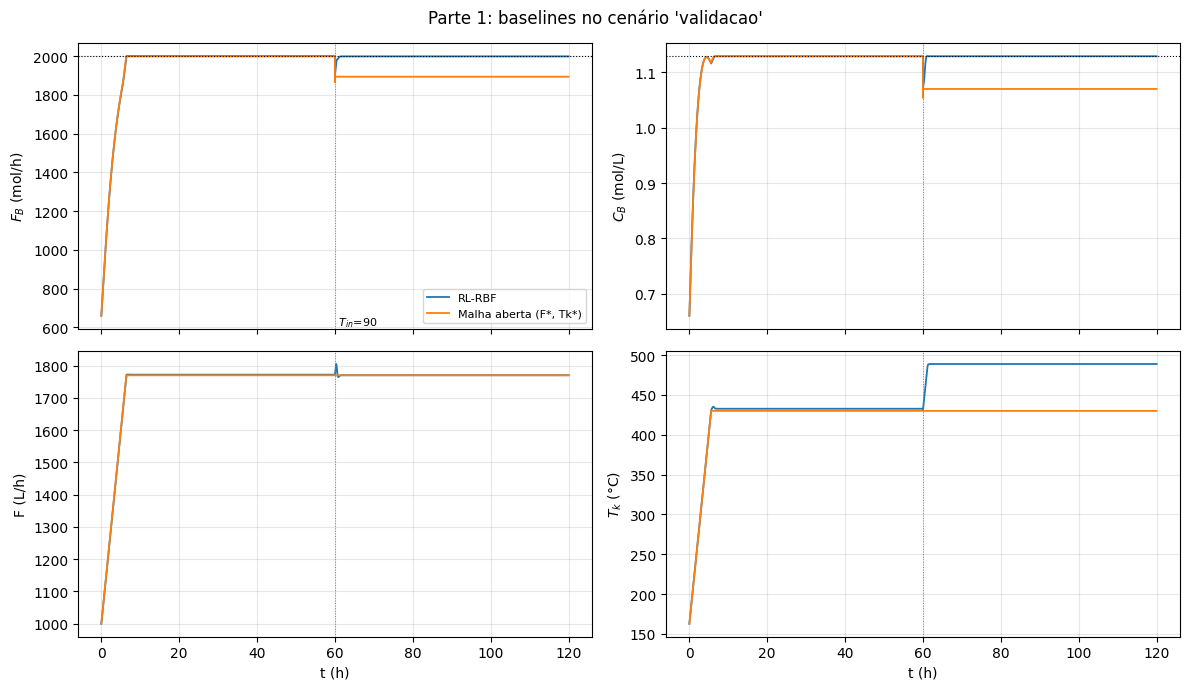

Cenário 'validacao'


,J,IAE_FB_h,perda_CB_h,J_apos_15h,CB_medio_final
RL-RBF,2.418,1.824,0.594,0.103,1.129
"Malha aberta (F*, Tk*)",8.656,4.947,3.709,6.347,1.070


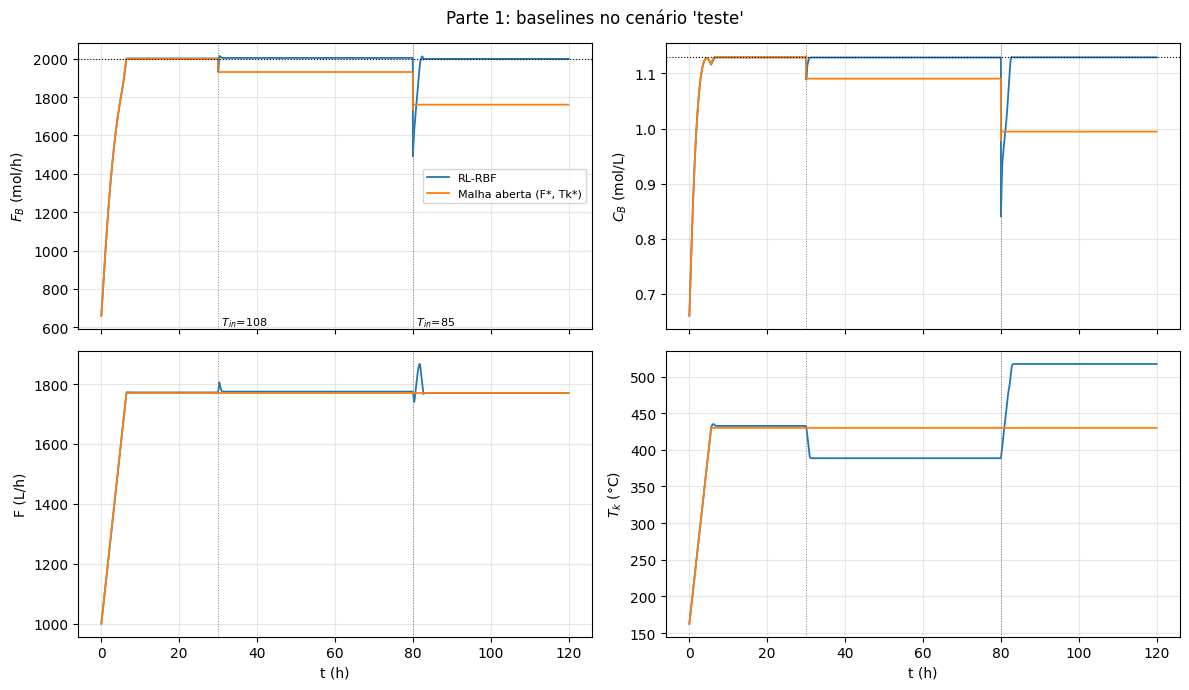

Cenário 'teste'


,J,IAE_FB_h,perda_CB_h,J_apos_15h,CB_medio_final
RL-RBF,2.986,2.120,0.866,0.671,1.129
"Malha aberta (F*, Tk*)",15.359,8.298,7.061,13.050,0.994


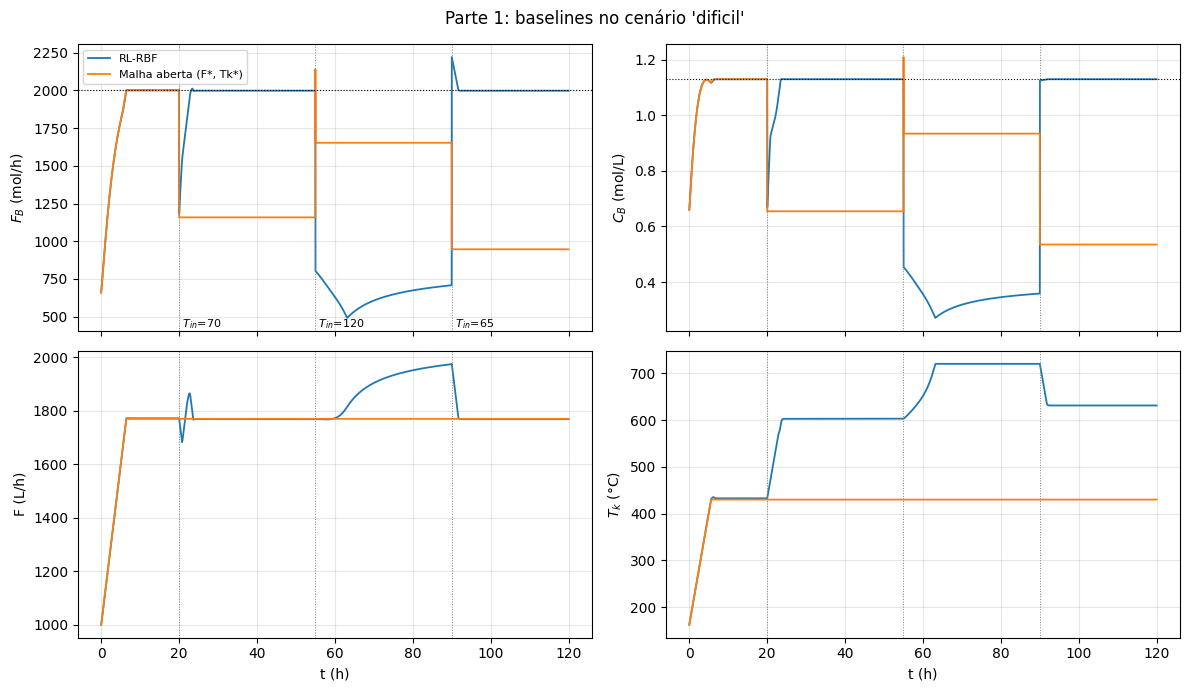

Cenário 'dificil'


,J,IAE_FB_h,perda_CB_h,J_apos_15h,CB_medio_final
RL-RBF,51.626,26.124,25.502,49.311,1.129
"Malha aberta (F*, Tk*)",75.489,38.358,37.131,73.180,0.535


In [6]:
VARS = ['t', 'FB', 'CB', 'F', 'Tk', 'T']

def save_baselines(trajs, path="baselines.npz"):
    """trajs[cenário][nome] = trajetória"""
    np.savez(path, **{f"{sc}|{n}|{v}": np.asarray(tr[v], dtype=float)
                      for sc, d in trajs.items() for n, tr in d.items() for v in VARS})

def load_baselines(path="baselines.npz"):
    z = np.load(path); out = {}
    for k in z.files:
        sc, n, v = k.split('|'); out.setdefault(sc, {}).setdefault(n, {})[v] = z[k]
    return out

def get_baselines(path="baselines.npz", weights="rlrbf_pesos.npz"):
    if os.path.exists(path):
        return load_baselines(path)
    from baselines_vdv import RLRBF, run_rlrbf
    agent = RLRBF(seed=0)
    if os.path.exists(weights):
        agent.load(weights)
    else:
        print("Treinando RL-RBF (~10-15 min)...")
        agent.train(n_episodes=500, ep_steps=6000, verbose=50); agent.save(weights)
    trajs = {sc: {"RL-RBF": run_rlrbf(agent, sc)} for sc in SCENARIOS}
    save_baselines(trajs, path)
    return trajs

def open_loop_policy(F_star=1770.0, Tk_star=430.0):
    env = VdVEnv()
    def pol(obs):
        s = (obs + 1) / 2 * (env._hi - env._lo) + env._lo
        return np.array([np.clip((F_star - s[3]) / 12, -1, 1), np.clip((Tk_star - s[4]) / 4.8, -1, 1)])
    return pol

def plot_comparison(trajs, scenario, title=None):
    fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for name, tr in trajs.items():
        ls = '--' if 'SAC' in name else '-'
        ax[0, 0].plot(tr['t'], tr['FB'], ls, label=name, lw=1.3)
        ax[0, 1].plot(tr['t'], tr['CB'], ls, lw=1.3)
        ax[1, 0].plot(tr['t'], tr['F'], ls, lw=1.3)
        ax[1, 1].plot(tr['t'], tr['Tk'], ls, lw=1.3)
    ax[0, 0].axhline(FB_SP, color='k', lw=0.8, ls=':')
    ax[0, 1].axhline(CB_STAR, color='k', lw=0.8, ls=':')
    for a, yl in zip(ax.ravel(), ['$F_B$ (mol/h)', '$C_B$ (mol/L)', 'F (L/h)', '$T_k$ (°C)']):
        a.set_ylabel(yl); a.grid(alpha=0.3)
        for k, Tin in SCENARIOS[scenario]:
            a.axvline(k * DT, color='gray', lw=0.7, ls=':')
    for k, Tin in SCENARIOS[scenario]:
        ax[0, 0].text(k * DT, ax[0, 0].get_ylim()[0], f" $T_{{in}}$={Tin:.0f}", fontsize=8, va='bottom')
    ax[1, 0].set_xlabel('t (h)'); ax[1, 1].set_xlabel('t (h)')
    ax[0, 0].legend(fontsize=8)
    fig.suptitle(title or f"Cenário: {scenario}")
    plt.tight_layout(); plt.show()

def metrics_table(trajs):
    return pd.DataFrame({n: metrics(t) for n, t in trajs.items()}).T.round(3)

baselines = get_baselines()
ref = {}
for sc in SCENARIOS:
    ref[sc] = dict(baselines[sc])
    ref[sc]['Malha aberta (F*, Tk*)'] = run_scenario(open_loop_policy(), sc)
    plot_comparison(ref[sc], sc, f"Parte 1: baselines no cenário '{sc}'")
    print(f"Cenário '{sc}'"); display(metrics_table(ref[sc]))

# Parte 2: treinamento do SAC

O código abaixo treina um SAC (Stable-Baselines3) com uma configuração inicial razoável. **Seu trabalho é melhorá-la**, usando apenas o cenário `validacao` para acompanhar o desempenho. Algumas dicas e armadilhas:

- Cada decisão do agente é mantida por `ACTION_REPEAT` passos de 0,01 h. Valores maiores aceleram o treino e alongam o horizonte efetivo do desconto $\gamma$ (com $\gamma = 0{,}99$ e `ACTION_REPEAT = 10`, o horizonte é ~10 h; as transições de $F$ e $T_k$ levam ~6 h).
- A **escala da recompensa** importa para o SAC: ela é comparada ao termo de entropia. Veja `REWARD_SCALE`, `W` e `EPS`.
- O treino começa de estados aleatórios (como no artigo); os cenários `teste` e `dificil` têm perturbações bem diferentes. Com `DIST_PROB > 0`, cada episódio de treino recebe 1 a 3 degraus aleatórios em $T_{in}$ (instantes aleatórios, valores sorteados em 55-135 °C, ajustável em `dist_range`), que é o tipo de perturbação do cenário `dificil`. O RL-RBF do baseline foi treinado sem perturbações e falha no `dificil`.
- Uma recompensa que apenas premia a redução do erro (Eq. 35) não penaliza "ficar parado" longe do setpoint. Experimente alternativas (por exemplo, uma penalidade $-|F_B - F_B^{SP}|$).
- Treine uma semente para explorar, e só depois rode 3 sementes na configuração final.
- Tempo esperado: ~15-25 min por semente na CPU do Colab com a configuração padrão.

In [14]:
from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback

# ---------------- Hiperparâmetros (modifique) ----------------
ACTION_REPEAT   = 10            # passos de 0,01 h por decisão (1 a 20)
EP_STEPS        = 3000          # duração do episódio de treino, em passos de 0,01 h
DIST_PROB       = 0.0           # prob. de um episódio de treino ter 1 a 3 degraus aleatórios em Tin (0 = sem perturbações)
TOTAL_DT_STEPS  = 1_500_000     # orçamento de simulação (máx. 3_000_000)
SAC_KWARGS = dict(
    learning_rate=3e-4, gamma=0.99, batch_size=256, buffer_size=100_000, tau=0.005,
    learning_starts=2000, train_freq=1, gradient_steps=1, ent_coef="auto",
    policy_kwargs=dict(net_arch=[128, 128]),
)
SEEDS = [0]                     # configuração final: use pelo menos 3 sementes, ex.: [0, 1, 2]
# -------------------------------------------------------------
assert TOTAL_DT_STEPS <= 3_000_000 and 1 <= ACTION_REPEAT <= 20
TOTAL_STEPS = TOTAL_DT_STEPS // ACTION_REPEAT   # número de decisões do agente

class EvalJ(BaseCallback):
    """Registra J no cenário 'validacao' a cada `every` decisões (apenas para acompanhar o aprendizado)."""
    def __init__(self, every=10_000):
        super().__init__(); self.every, self.log = every, []
    def _on_step(self):
        if self.num_timesteps % self.every == 0:
            tr = run_scenario(lambda o: self.model.predict(o, deterministic=True)[0], "validacao", action_repeat=ACTION_REPEAT)
            m = metrics(tr); self.log.append((self.num_timesteps, m['J']))
            print(f"  decisões: {self.num_timesteps:>8d} | J = {m['J']:.3f}")
        return True

def train_sac(seed):
    env = Monitor(VdVEnv(mode="train", action_repeat=ACTION_REPEAT, episode_steps=EP_STEPS,
                         dist_prob=DIST_PROB, reward_fn=REWARD_FN))
    model = SAC("MlpPolicy", env, seed=seed, verbose=0, **SAC_KWARGS)
    cb = EvalJ()
    model.learn(total_timesteps=TOTAL_STEPS, callback=cb)
    model.save(f"sac_seed{seed}")
    return model, cb.log

models, curves = {}, {}
for seed in SEEDS:
    print(f"== Semente {seed} ==")
    models[seed], curves[seed] = train_sac(seed)

== Semente 0 ==
  decisões:    10000 | J = 5.893
  decisões:    20000 | J = 70.944
  decisões:    30000 | J = 24.337
  decisões:    40000 | J = 17.200
  decisões:    50000 | J = 12.994
  decisões:    60000 | J = 12.841
  decisões:    70000 | J = 13.436
  decisões:    80000 | J = 11.797
  decisões:    90000 | J = 15.422
  decisões:   100000 | J = 14.741
  decisões:   110000 | J = 15.228
  decisões:   120000 | J = 16.819
  decisões:   130000 | J = 17.562
  decisões:   140000 | J = 16.133
  decisões:   150000 | J = 21.524


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


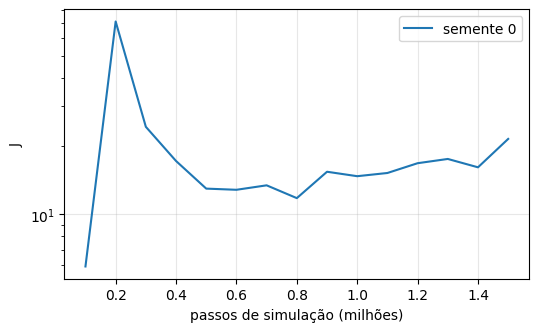

In [15]:
# Curvas de aprendizado (J no cenário 'validacao'; menor é melhor)
plt.figure(figsize=(6, 3.5))
for seed, c in curves.items():
    c = np.array(c); plt.plot(c[:, 0] * ACTION_REPEAT / 1e6, c[:, 1], label=f"semente {seed}")
plt.xlabel("passos de simulação (milhões)"); plt.ylabel("J"); plt.yscale("log"); plt.grid(alpha=0.3); plt.legend(); plt.show()

# Parte 3: comparação nos três cenários e análise

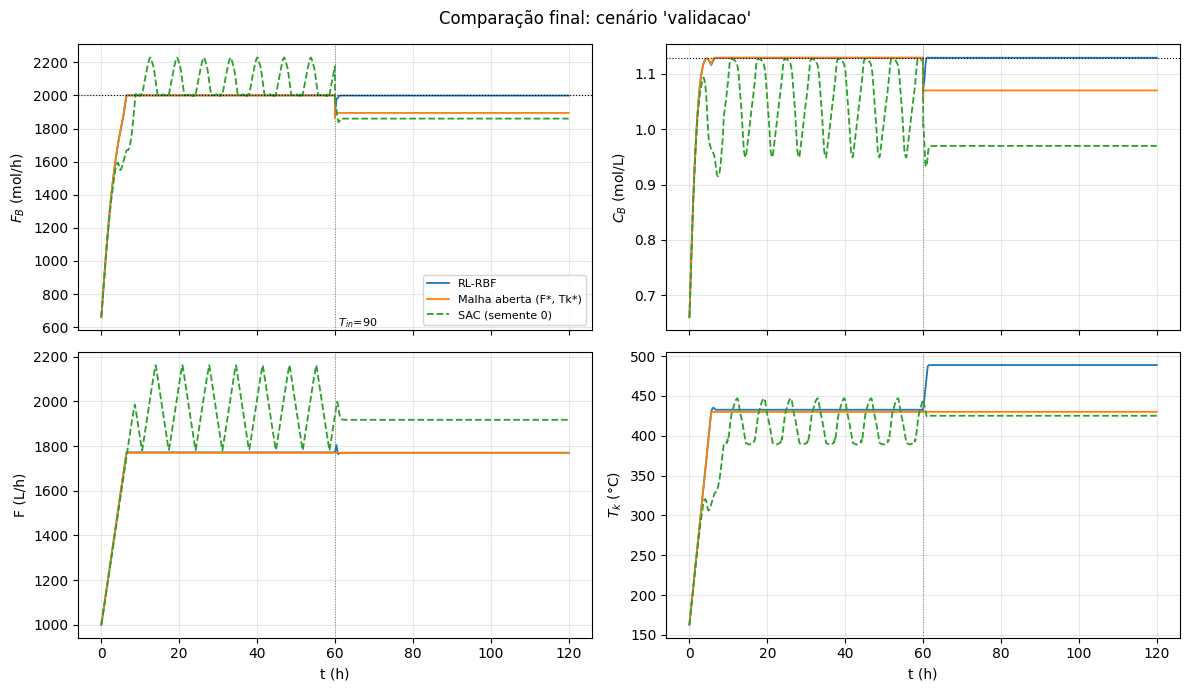

Cenário 'validacao'


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,J,IAE_FB_h,perda_CB_h,J_apos_15h,CB_medio_final
RL-RBF,2.418,1.824,0.594,0.103,1.129
"Malha aberta (F*, Tk*)",8.656,4.947,3.709,6.347,1.070
SAC (semente 0),21.491,8.510,12.981,17.230,0.970


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


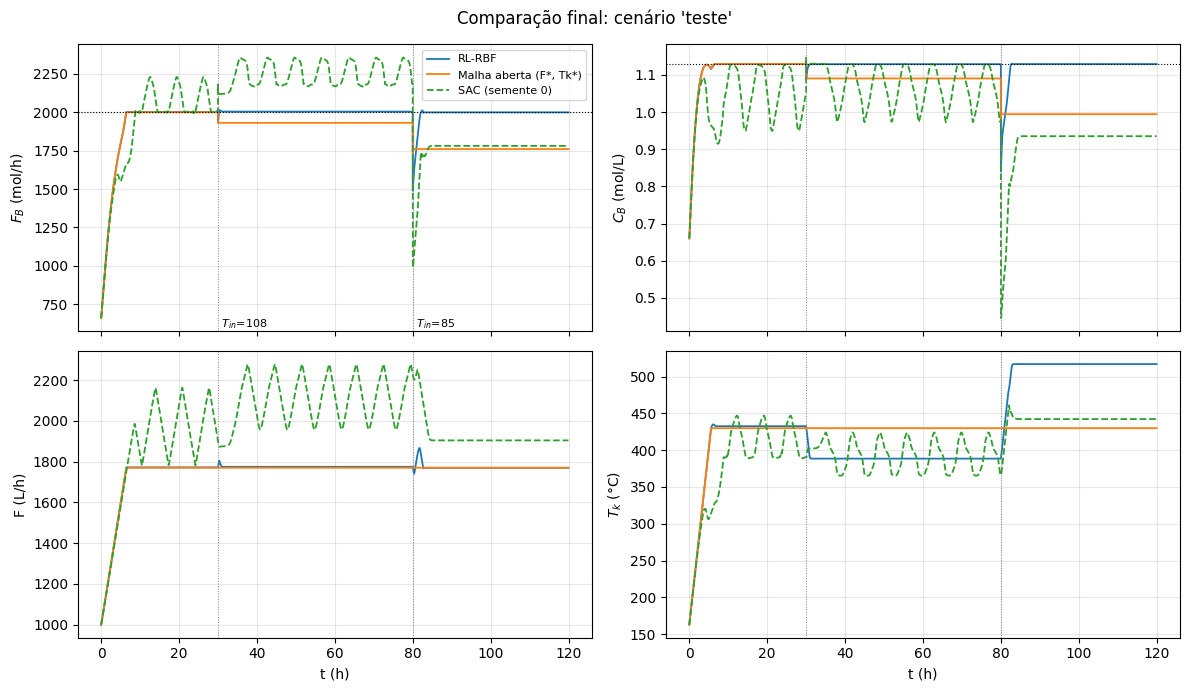

Cenário 'teste'


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,J,IAE_FB_h,perda_CB_h,J_apos_15h,CB_medio_final
RL-RBF,2.986,2.120,0.866,0.671,1.129
"Malha aberta (F*, Tk*)",15.359,8.298,7.061,13.050,0.994
SAC (semente 0),27.102,14.226,12.876,22.841,0.935


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


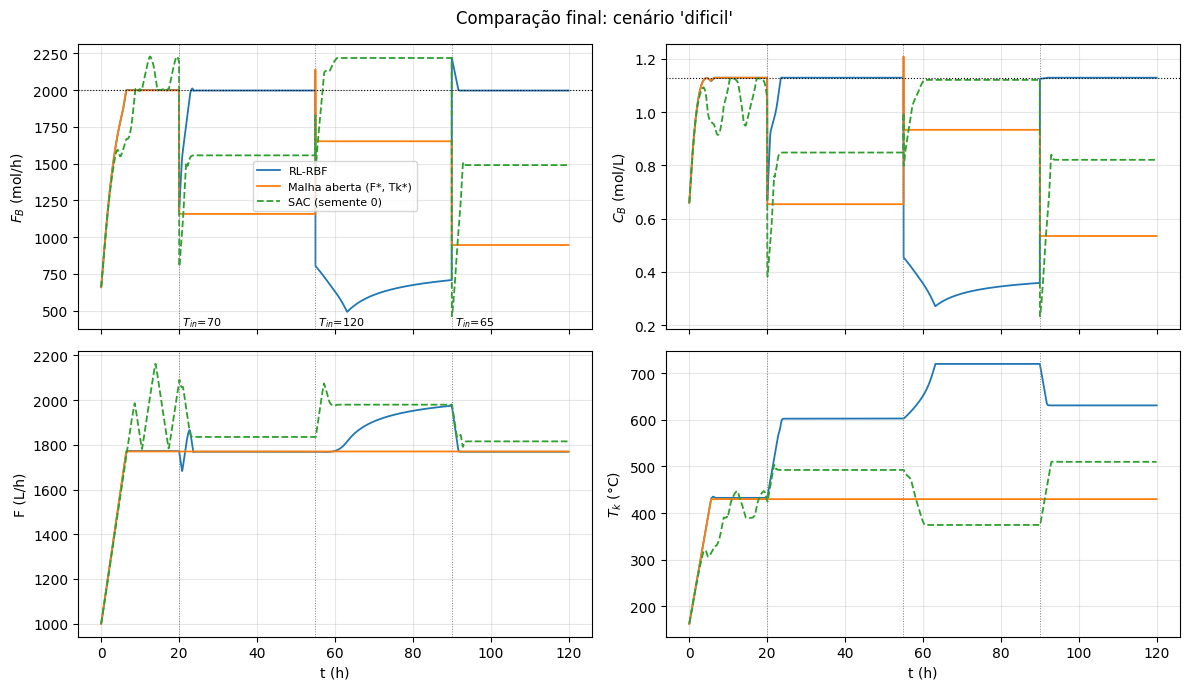

Cenário 'dificil'


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,J,IAE_FB_h,perda_CB_h,J_apos_15h,CB_medio_final
RL-RBF,51.626,26.124,25.502,49.311,1.129
"Malha aberta (F*, Tk*)",75.489,38.358,37.131,73.180,0.535
SAC (semente 0),44.081,23.203,20.878,39.820,0.821


In [16]:
final = {}
for sc in SCENARIOS:
    sac_trajs = {}
    for seed, m in models.items():
        pol = lambda o, m=m: m.predict(o, deterministic=True)[0]
        sac_trajs[f"SAC (semente {seed})"] = run_scenario(pol, sc, action_repeat=ACTION_REPEAT)
    all_trajs = {**ref[sc], **sac_trajs}
    plot_comparison(all_trajs, sc, f"Comparação final: cenário '{sc}'")
    tab = metrics_table(all_trajs); final[sc] = tab
    print(f"Cenário '{sc}'"); display(tab)
    if len(sac_trajs) > 1:
        sac_tab = tab.loc[list(sac_trajs)]
        print("SAC: média ± desvio padrão entre sementes")
        display(pd.DataFrame({"média": sac_tab.mean(), "desvio": sac_tab.std()}).round(3).T)

## Perguntas

Responda de forma objetiva (3 a 6 linhas cada), com base nos seus resultados.

1. **Baseline.** Descreva o comportamento do RL-RBF nos três cenários e identifique em que condições ele falha no `dificil` (veja $T$ e $T_k$). Ele foi treinado sem perturbações em $T_{in}$: por que consegue rejeitá-las? (Dica: observe o que acontece com $T_k$ de regime permanente em cada cenário e o que a política enxerga.)
2. **Recompensa.** O que você mudou na recompensa (ou por que decidiu mantê-la)? Mostre o efeito (por exemplo, J antes/depois ou uma trajetória).
3. **Hiperparâmetros.** Quais hiperparâmetros (incluindo `ACTION_REPEAT`) tiveram maior impacto? Justifique a partir dos conceitos vistos em aula.
4. **Generalização e variabilidade.** Qual foi a dispersão de J entre sementes? O desempenho nos cenários `teste` e `dificil` foi coerente com o do `validacao`? Se não, o que isso indica sobre o que o agente aprendeu?
5. **RBFs × redes neurais.** O artigo argumenta que aproximadores lineares (RBFs) têm convergência garantida, enquanto redes neurais podem divergir. Você observou alguma instabilidade no treino do SAC? O que o SAC traz (entropia, duplo crítico, *replay buffer*) que o actor-critic com RBFs não traz? E o que ele perde em garantias? Compare também o número de parâmetros e a sensibilidade a hiperparâmetros.
6. **Uso em planta real.** Treinar o agente diretamente na planta não é aceitável. Que abordagem de duas etapas o artigo propõe? Que riscos (restrições, segurança, estabilidade, diferença simulador-planta) permanecem para uma política SAC?

**Suas respostas:**

1.
2.
3.
4.
5.
6.